# Nærhet, tetthet og klynger: kNN og DBSCAN

Tre spørsmål vi stiller til punktdata, med serveringssteder (restaurant, kafé, bar, pub, fast food)
fra OpenStreetMap i Kristiansand sentrum som eksempel:

1. **Nærhet**: hvem er nærmest hvem? (*k nearest neighbours*, kNN)
2. **Tetthet**: hvor er det mest av noe? (rutenett og kernel density)
3. **Klynger**: hvor ligger ting i grupper? (**DBSCAN**, og k-means som kontrast)

Hver analyse vises i Python (geopandas / scikit-learn), som SQL for **PostGIS** og som SQL i **DuckDB**.

| | Python | PostGIS | DuckDB spatial |
|---|---|---|---|
| kNN | `NearestNeighbors`, `sjoin_nearest` | `<->` + `LATERAL` | vindusfunksjon (`QUALIFY`) |
| DBSCAN | `sklearn.cluster.DBSCAN` | `ST_ClusterDBSCAN` | **finnes ikke**, men kan bygges med rekursiv CTE |
| k-means | `sklearn.cluster.KMeans` | `ST_ClusterKMeans` | **finnes ikke** |

**PostGIS er ikke installert her**, så PostGIS-eksemplene står som kodeblokker som ikke er kjørt.
DuckDB-eksemplene kjøres, og DBSCAN-varianten vår sjekkes mot scikit-learn.

In [1]:
from pathlib import Path

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import KernelDensity, NearestNeighbors

ox.settings.use_cache = True
ox.settings.cache_folder = "cache"
ox.settings.log_console = False

DATA = Path("data")
DATA.mkdir(exist_ok=True)

# Okabe–Ito (fargeblind-sikker) til klynger, grått til støy
FARGER = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#F0E442", "#000000"]
STOY = "#B0B0B0"

## Data: serveringssteder i Kristiansand sentrum

Hentes én gang fra OSM (3 km rundt stasjonen) og lagres i `data/servering.gpkg`.
**Viktig:** vi projiserer til UTM 33N (EPSG:25833), slik at avstander er i **meter**.
Både `eps` i DBSCAN og `ST_DWithin` i SQL forutsetter at koordinatene har meter som enhet.
Med lengde/bredde (grader) ville `eps = 150` bety 150 grader.

In [2]:
SERVERING_FIL = DATA / "servering.gpkg"
if SERVERING_FIL.exists():
    servering = gpd.read_file(SERVERING_FIL)
else:
    servering = ox.features.features_from_point(
        (58.1467, 7.9956),  # Kristiansand stasjon
        tags={"amenity": ["restaurant", "cafe", "bar", "pub", "fast_food"]},
        dist=3000,
    )
    servering = servering.assign(geometry=servering.representative_point())[["name", "amenity", "geometry"]]
    servering = servering.reset_index(drop=True)
    servering.to_file(SERVERING_FIL)

servering = servering.to_crs(25833)
servering["id"] = range(len(servering))
servering["x"] = servering.geometry.x
servering["y"] = servering.geometry.y
XY = servering[["x", "y"]].to_numpy()

print(len(servering), "serveringssteder")
servering["amenity"].value_counts().to_frame()

128 serveringssteder


,count
amenity,
restaurant,60
cafe,36
fast_food,22
pub,5
bar,5


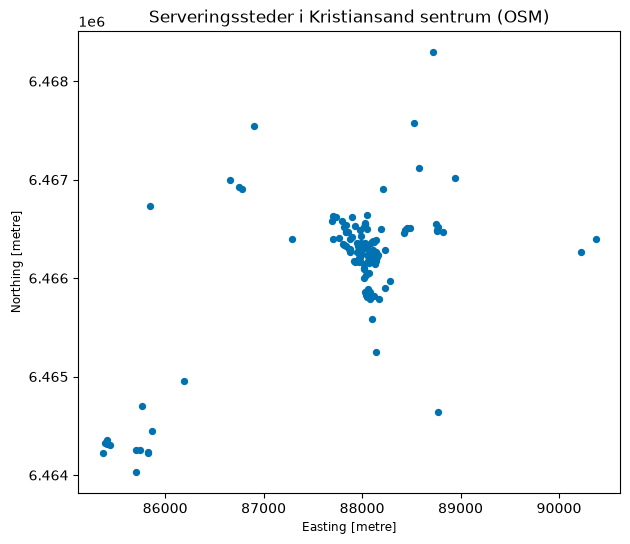

In [3]:
fig, ax = plt.subplots(figsize=(7, 6))
servering.plot(ax=ax, markersize=18, color=FARGER[0])
ax.set_title("Serveringssteder i Kristiansand sentrum (OSM)")
ax.set_aspect("equal")
plt.show()

## 1. Nærhet: k nærmeste naboer (kNN)

kNN-søk: for hvert punkt, finn de *k* nærmeste punktene. Avstanden her er **luftlinje**.
Langs vegnett eller i reisetid kan svaret bli et helt annet (se `kristiansand_osmnx.ipynb`).

*Merk:* «kNN» brukes også om en klassifikasjonsmetode (*k-nearest neighbours classifier*:
et punkt får klassen til flertallet av de k nærmeste). Her bruker vi kNN som **søk** etter naboer.
Det er også byggesteinen i DBSCAN, som vi kommer til under.

### Python: scikit-learn og geopandas

Vi finner de tre nærmeste naboene til hvert sted. Første nabo er punktet selv (avstand 0), så vi ber om k+1.

In [4]:
K = 3
nn = NearestNeighbors(n_neighbors=K + 1).fit(XY)
avstand, indeks = nn.kneighbors(XY)

servering["avstand_nabo1"] = avstand[:, 1]
servering["avstand_nabo3"] = avstand[:, K]
servering[["name", "amenity", "avstand_nabo1", "avstand_nabo3"]].sort_values("avstand_nabo3").head(5)

,name,amenity,avstand_nabo1,avstand_nabo3
124,Lille Bodega,restaurant,15.054493,21.768551
121,Pincho Nation,restaurant,7.065360,21.950896
40,Patricks Pub,pub,10.557930,22.750915
120,Pincho Nation,restaurant,6.817595,24.304674
22,Slakter Sørensen,restaurant,14.226745,24.587756


Til det nærmeste stedet av en *annen type* bruker vi `sjoin_nearest` i geopandas.
Eksempel: hvor langt har hver restaurant til nærmeste pub eller bar?

In [5]:
puber = servering[servering["amenity"].isin(["pub", "bar"])][["name", "geometry"]]
restauranter = servering[servering["amenity"] == "restaurant"][["name", "geometry"]]

til_pub = restauranter.sjoin_nearest(puber, how="left", distance_col="avstand_m", rsuffix="pub")
til_pub[["name_left", "name_pub", "avstand_m"]].sort_values("avstand_m").head(5).round(0)

,name_left,name_pub,avstand_m
38,Big Horn Steak House,Charlie's Bar,11.0
10,Havana,Javel pub,12.0
11,Bakgården,Harvey's,13.0
22,Slakter Sørensen,Patricks Pub,14.0
48,Le Monde tapas,Patricks Pub,23.0


### PostGIS (ikke kjørt her)

Lastes inn med f.eks. `ogr2ogr -f PostgreSQL PG:"dbname=gis" data/servering.gpkg -nln servering -t_srs EPSG:25833`.
Operatoren `<->` gir avstand og kan bruke en GiST-indeks. Den gjør kNN-søk raskt, fordi PostGIS
slipper å regne ut avstand til alle punkter.

```sql
CREATE INDEX servering_geom_idx ON servering USING GIST (geom);

-- de 3 nærmeste naboene til hvert sted
SELECT a.name AS fra, n.name AS til, n.avstand_m
FROM servering a
CROSS JOIN LATERAL (
    SELECT b.name, a.geom <-> b.geom AS avstand_m
    FROM servering b
    WHERE b.id <> a.id
    ORDER BY a.geom <-> b.geom
    LIMIT 3
) n;

-- alt innenfor en terskel (her 150 m), bruker også indeksen
SELECT a.name, count(*) AS antall_naboer
FROM servering a
JOIN servering b ON ST_DWithin(a.geom, b.geom, 150) AND a.id <> b.id
GROUP BY a.name;
```

### DuckDB

DuckDB spatial har `ST_Distance` og `ST_DWithin`, men ingen `<->`-operator og ingen kNN-indeks
som i PostGIS. Da bruker vi en vindusfunksjon: rangér alle par etter avstand per punkt, behold de k første.
Det er en full krysskobling, O(n²), som er helt greit for noen tusen punkter, men ikke for millioner.

In [6]:
con = duckdb.connect()
con.sql("INSTALL spatial; LOAD spatial;")
punkter = servering[["id", "name", "amenity", "x", "y"]]  # DuckDB leser DataFrames direkte
con.sql("CREATE TABLE servering AS SELECT id, name, amenity, ST_Point(x, y) AS geom FROM punkter")

con.sql("""
    SELECT a.name AS fra, b.name AS til,
           round(ST_Distance(a.geom, b.geom)) AS avstand_m,
           row_number() OVER (PARTITION BY a.id ORDER BY ST_Distance(a.geom, b.geom)) AS rang
    FROM servering a
    JOIN servering b ON a.id <> b.id
    QUALIFY rang <= 3
    ORDER BY a.id, rang
    LIMIT 9
""").df()

,fra,til,avstand_m,rang
0,Amigos,Brygga isbar,32.0,1
1,Amigos,Dolly Dimples Fiskebrygga,51.0,2
2,Amigos,Hos Moi,57.0,3
3,Café Generalen,Vinbaren på Mølla,596.0,1
4,Café Generalen,Pizzabakeren Grim,638.0,2
5,Café Generalen,Grim Kinamat,645.0,3
6,Natmanden Kafe,Donut Palace,411.0,1
7,Natmanden Kafe,Kvadraturen Grill og Kiosk,439.0,2
8,Natmanden Kafe,Midnight Cafe,474.0,3


Sjekk at DuckDB og scikit-learn gir samme tredje-nærmeste avstand:

In [7]:
duck_k3 = con.sql("""
    SELECT a.id, ST_Distance(a.geom, b.geom) AS d
    FROM servering a JOIN servering b ON a.id <> b.id
    QUALIFY row_number() OVER (PARTITION BY a.id ORDER BY ST_Distance(a.geom, b.geom)) = 3
    ORDER BY a.id
""").df()
print("Samme avstand til nabo nr. 3:", np.allclose(duck_k3["d"], servering["avstand_nabo3"]))

Samme avstand til nabo nr. 3: True


## 2. Tetthet: hvor er det mest?

Før vi finner klynger: den enkleste måten å se «mest av noe» på er å **telle per rute**.
Her ruter på 250 m (som SSB-rutenettet). Resultatet avhenger av **cellestørrelsen** og av
hvor rutenettet starter. Samme data gir ulike kart. Kernel density (KDE) glatter ut
rutegrensene, men da må du velge **bandwidth** i stedet.

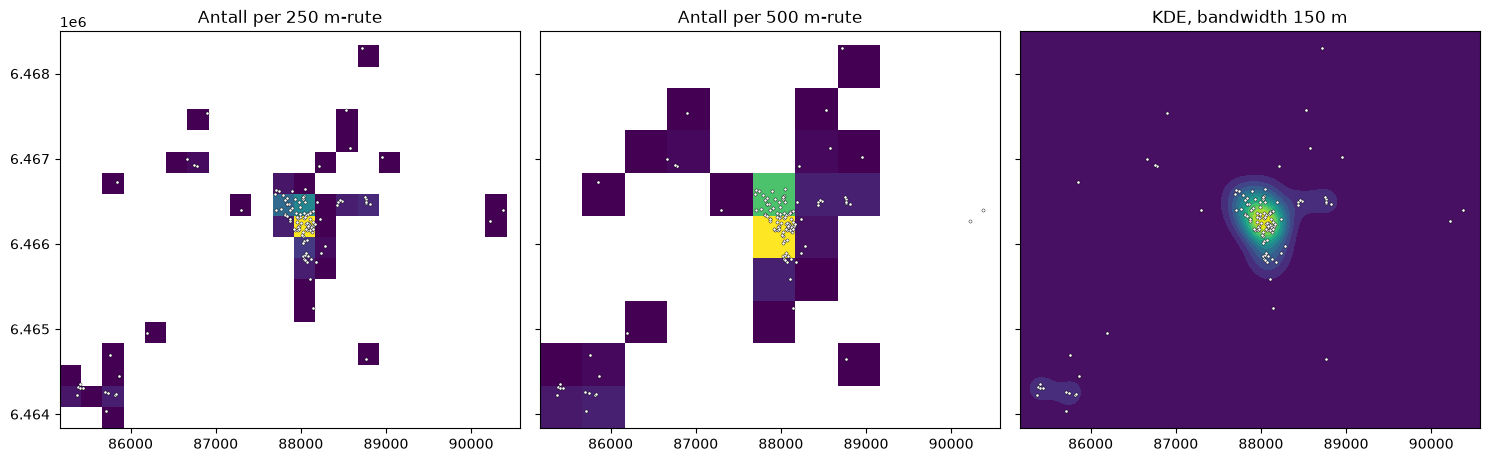

In [8]:
def tell_per_rute(xy, celle):
    ix = np.floor(xy[:, 0] / celle).astype(int)
    iy = np.floor(xy[:, 1] / celle).astype(int)
    return pd.Series(1, index=pd.MultiIndex.from_arrays([ix, iy])).groupby(level=[0, 1]).sum()


fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
xmin, ymin = XY.min(axis=0) - 200
xmax, ymax = XY.max(axis=0) + 200

for ax, celle in zip(axes[:2], [250, 500]):
    ax.hist2d(XY[:, 0], XY[:, 1], bins=[np.arange(xmin, xmax, celle), np.arange(ymin, ymax, celle)],
              cmap="viridis", cmin=1)
    ax.set_title(f"Antall per {celle} m-rute")

BANDBREDDE = 150
kde = KernelDensity(bandwidth=BANDBREDDE).fit(XY)
gx, gy = np.meshgrid(np.linspace(xmin, xmax, 200), np.linspace(ymin, ymax, 200))
tetthet = np.exp(kde.score_samples(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
axes[2].contourf(gx, gy, tetthet * 1e6, levels=12, cmap="viridis")
axes[2].set_title(f"KDE, bandwidth {BANDBREDDE} m")

for ax in axes:
    ax.scatter(XY[:, 0], XY[:, 1], s=5, c="white", edgecolor="k", linewidth=0.3)
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

Tetthet gir en **kontinuerlig flate**, men ingen avgrensede grupper. Spørsmålet «hvor mange
klynger er det, og hvilke steder hører til hvilken?» krever klyngeanalyse.

## 3. Klynger med DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) har to parametre:

- **`eps`**: maks avstand mellom to punkter for at de regnes som naboer
- **`min_samples`**: minste antall punkter (inkl. punktet selv) innen `eps` for at et punkt er et **kjernepunkt**

Algoritmen:

1. **Kjernepunkt**: har minst `min_samples` punkter innen `eps`.
2. **Klynge**: kjernepunkter som ligger innen `eps` av hverandre, henger sammen i samme klynge (kjeder av kjernepunkter gir klynger i vilkårlig form).
3. **Randpunkt**: ikke kjerne selv, men innen `eps` av et kjernepunkt. Tilhører den klyngen.
4. **Støy**: alle andre. Får etikett `-1` (i PostGIS `NULL`).

Du trenger ikke velge antall klynger på forhånd.

### Velge `eps`: k-distance-plott

Tommelfingerregel: sett `min_samples` ut fra hva som er «en gruppe» i problemet ditt, og se på
avstanden til nabo nr. `min_samples` for alle punkter, sortert. `eps` velges der kurven knekker:
til venstre ligger punkter i tette områder, til høyre spredte punkter (støy).
Knekken er ofte tvetydig. Se derfor alltid på kartet og forklar valget.

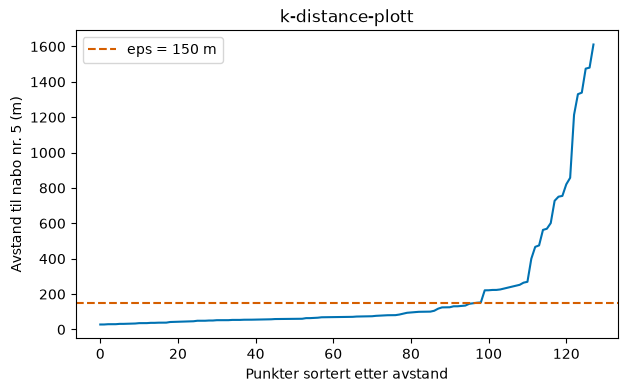

In [9]:
MIN_SAMPLES = 5
d_k = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(XY).kneighbors(XY)[0][:, -1])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(d_k, color=FARGER[0])
ax.axhline(150, color=FARGER[1], linestyle="--", label="eps = 150 m")
ax.set_xlabel("Punkter sortert etter avstand")
ax.set_ylabel(f"Avstand til nabo nr. {MIN_SAMPLES} (m)")
ax.set_title("k-distance-plott")
ax.legend()
plt.show()

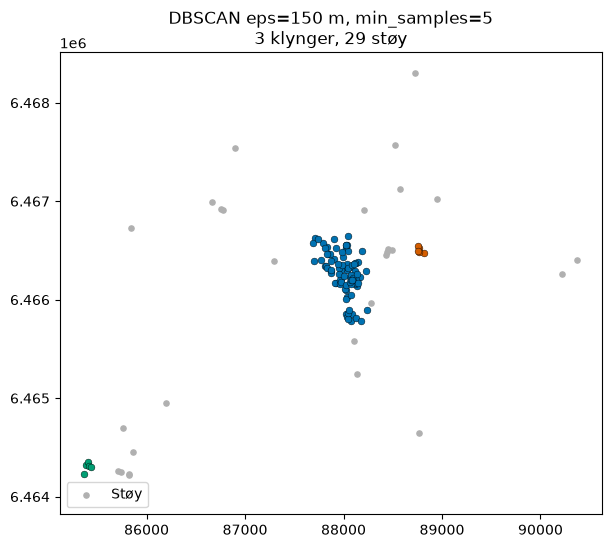

,antall,kafeer
dbscan,,
-1,29,6
0,89,26
1,5,2
2,5,2


In [10]:
def kartlegg(ax, xy, etikett, tittel):
    ax.scatter(*xy[etikett == -1].T, s=14, c=STOY, label="Støy")
    for i, k in enumerate(sorted(set(etikett) - {-1})):
        ax.scatter(*xy[etikett == k].T, s=24, c=FARGER[i % len(FARGER)], edgecolor="k", linewidth=0.3)
    ant = len(set(etikett) - {-1})
    ax.set_title(f"{tittel}\n{ant} klynger, {(etikett == -1).sum()} støy")
    ax.set_aspect("equal")


EPS = 150
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(XY)
servering["dbscan"] = db.labels_

fig, ax = plt.subplots(figsize=(7, 6))
kartlegg(ax, XY, db.labels_, f"DBSCAN eps={EPS} m, min_samples={MIN_SAMPLES}")
ax.legend(loc="lower left")
plt.show()

servering.groupby("dbscan").agg(antall=("id", "size"), kafeer=("amenity", lambda s: (s == "cafe").sum()))

### Parametrene styrer svaret

Samme data, tre innstillinger. Små `eps` gir mange små klynger og mye støy. Store `eps` slår
alt sammen til én stor klynge. **Parametrene må følge med kartet.**

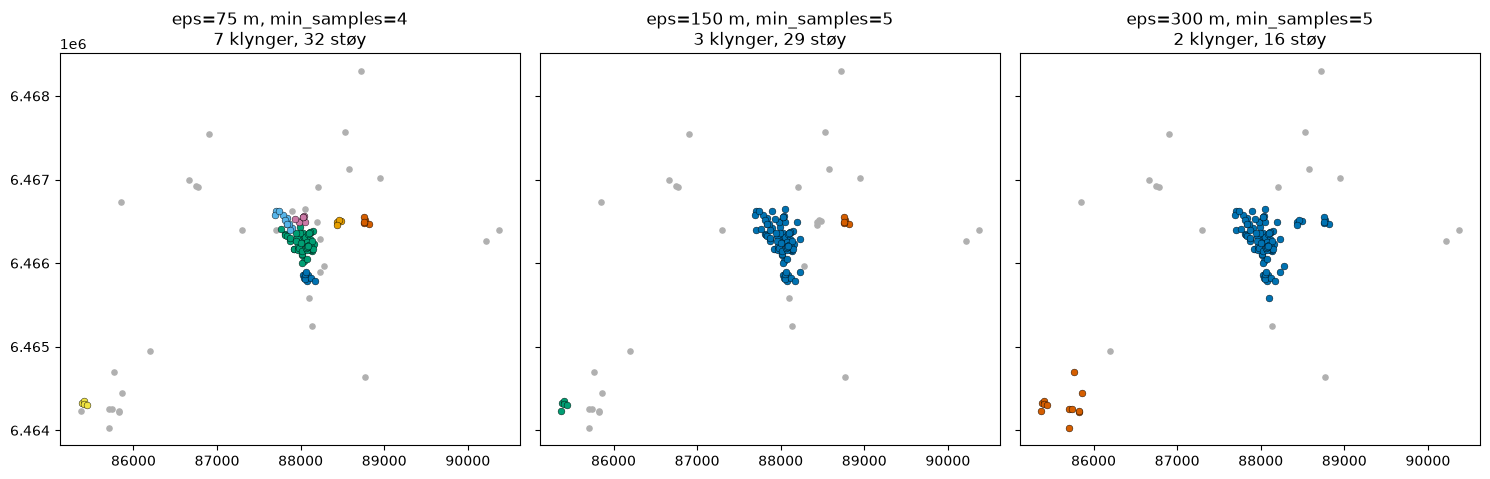

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, (eps, ms) in zip(axes, [(75, 4), (150, 5), (300, 5)]):
    kartlegg(ax, XY, DBSCAN(eps=eps, min_samples=ms).fit_predict(XY), f"eps={eps} m, min_samples={ms}")
plt.tight_layout()
plt.show()

### K-means som kontrast

K-means krever at du velger antall klynger (*k*) og plasserer **alle** punkter i en klynge. Det finnes
ingen støy, og klyngene blir runde og jevnt store. Det passer for «del opp i k distrikter», mens DBSCAN
passer for «finn de tette områdene». (Ikke bland sammen k i k-means og k i kNN.)

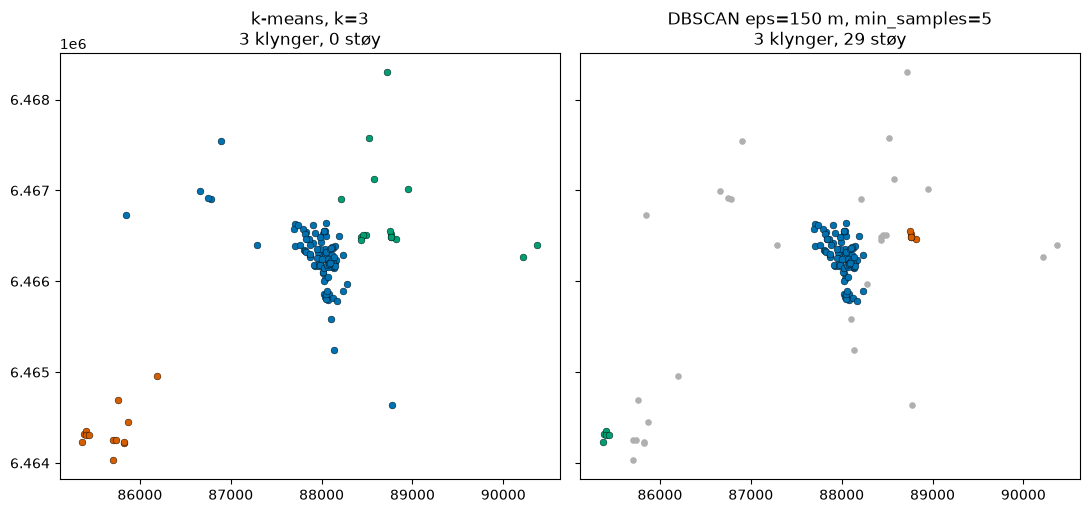

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
kartlegg(axes[0], XY, KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(XY), "k-means, k=3")
kartlegg(axes[1], XY, db.labels_, f"DBSCAN eps={EPS} m, min_samples={MIN_SAMPLES}")
plt.tight_layout()
plt.show()

### PostGIS (ikke kjørt her)

PostGIS har klyngefunksjoner som **vindusfunksjoner**. Kolonnen må være i et projisert koordinatsystem
(meter). Støy får `NULL`.

```sql
-- DBSCAN: eps i meter, minpoints tilsvarer min_samples
CREATE TABLE servering_klynge AS
SELECT id, name, geom,
       ST_ClusterDBSCAN(geom, eps := 150, minpoints := 5) OVER () AS klynge
FROM servering;

-- antall og utstrekning per klynge (støy = NULL hoppes over)
SELECT klynge,
       count(*) AS antall,
       ST_ConvexHull(ST_Collect(geom)) AS omriss
FROM servering_klynge
WHERE klynge IS NOT NULL
GROUP BY klynge;

-- k-means med k = 3
SELECT id, ST_ClusterKMeans(geom, 3) OVER () AS klynge FROM servering;

-- enklere variant uten min_samples: alt som henger sammen innen 150 m (single linkage)
SELECT unnest(ST_ClusterWithin(geom, 150)) FROM servering;
```

Sjekk at `minpoints` teller punktet selv på samme måte som `min_samples` i din PostGIS-versjon,
og sammenlign gjerne med scikit-learn på samme data.

### DuckDB

DuckDB spatial (versjon under) har `ST_DWithin` og `ST_Distance`, men **ingen** `ST_ClusterDBSCAN`
eller `ST_ClusterKMeans`. Vi sjekker:

In [13]:
print("duckdb", duckdb.__version__)
con.sql("""
    SELECT DISTINCT function_name FROM duckdb_functions()
    WHERE function_name ILIKE '%cluster%' OR function_name ILIKE '%dbscan%' OR function_name ILIKE '%kmeans%'
""").df()

duckdb 2.0.0


,function_name


Ingen treff. DBSCAN er likevel ren grafteori, og kan skrives i vanlig SQL:

1. **Naboer**: alle par innen `eps` (`ST_DWithin`).
2. **Kjernepunkter**: punkter med minst `min_samples` naboer (inkl. seg selv).
3. **Klynger**: sammenhengende grupper av kjernepunkter, via en **rekursiv CTE** som sprer en etikett langs nabokantene. Klyngens id er laveste punkt-id i gruppen.
4. **Randpunkter**: ikke-kjerner med en kjerne i nærheten får klyngen til nærmeste kjernepunkt.
5. **Støy**: resten (`NULL`).

In [14]:
def dbscan_duckdb(con, eps, min_samples):
    """DBSCAN i ren SQL. Returnerer DataFrame med id og klynge (NULL = støy)."""
    return con.sql(f"""
        WITH RECURSIVE
        kant AS (
            SELECT a.id AS a, b.id AS b, ST_Distance(a.geom, b.geom) AS d
            FROM servering a JOIN servering b ON ST_DWithin(a.geom, b.geom, {eps})
        ),
        kjerne AS (
            SELECT a AS id FROM kant GROUP BY a HAVING count(*) >= {min_samples}
        ),
        kjerne_kant AS (
            SELECT a, b FROM kant
            WHERE a IN (SELECT id FROM kjerne) AND b IN (SELECT id FROM kjerne)
        ),
        -- spre etiketten fra hvert kjernepunkt langs kantene mellom kjernepunkter
        rekke(id, etikett) AS (
            SELECT id, id FROM kjerne
            UNION
            SELECT rekke.id, kjerne_kant.b
            FROM rekke JOIN kjerne_kant ON kjerne_kant.a = rekke.etikett
        ),
        kjerne_klynge AS (
            SELECT id, min(etikett) AS klynge FROM rekke GROUP BY id
        ),
        -- randpunkter: nærmeste kjernepunkt innen eps
        rand AS (
            SELECT kant.a AS id, kjerne_klynge.klynge,
                   row_number() OVER (PARTITION BY kant.a ORDER BY kant.d) AS rang
            FROM kant JOIN kjerne_klynge ON kjerne_klynge.id = kant.b
            WHERE kant.a NOT IN (SELECT id FROM kjerne)
        )
        SELECT s.id,
               coalesce(kk.klynge, r.klynge) AS klynge
        FROM servering s
        LEFT JOIN kjerne_klynge kk ON kk.id = s.id
        LEFT JOIN rand r ON r.id = s.id AND r.rang = 1
        ORDER BY s.id
    """).df()


duck = dbscan_duckdb(con, EPS, MIN_SAMPLES)
duck["klynge"].value_counts(dropna=False).to_frame()

,count
klynge,
0,89
<NA>,29
3,5
94,5


**Verifisering:** ARI (*adjusted Rand index*) er 1,0 når to klyngeinndelinger er identiske
(etikettene kan være nummerert ulikt). Randpunkter som ligger innen `eps` av flere klynger
er tvetydige, så metodene kan avvike litt der (ved `eps=75` havner ett eller to randpunkter i ulik klynge,
ARI ≈ 0,98). Kjernepunktene og antall klynger er like.

In [15]:
for eps, ms in [(75, 4), (150, 5), (300, 5)]:
    sk = DBSCAN(eps=eps, min_samples=ms).fit_predict(XY)
    dd = dbscan_duckdb(con, eps, ms)["klynge"].fillna(-1).to_numpy()
    print(f"eps={eps:>3}, min_samples={ms}: sklearn {len(set(sk) - {-1})} klynger, "
          f"DuckDB {len(set(dd) - {-1})} klynger, ARI = {adjusted_rand_score(sk, dd):.3f}")

eps= 75, min_samples=4: sklearn 7 klynger, DuckDB 7 klynger, ARI = 0.980
eps=150, min_samples=5: sklearn 3 klynger, DuckDB 3 klynger, ARI = 1.000
eps=300, min_samples=5: sklearn 2 klynger, DuckDB 2 klynger, ARI = 1.000


Det er ikke raskt (kantene er O(n²) uten romlig indeks), men for noen tusen punkter går det fint,
og du får klyngene rett inn i en SQL-pipeline. For store datasett: bruk PostGIS, eller kjør
scikit-learn og skriv resultatet tilbake. Til slutt lagrer vi resultatet i en GeoPackage og lager
klyngeomriss (tilsvarer `ST_ConvexHull(ST_Collect(...))` i PostGIS):

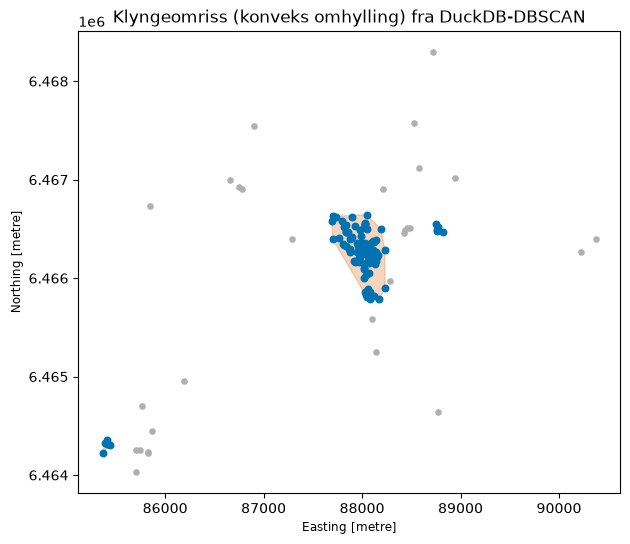

In [16]:
servering["klynge_duckdb"] = duck["klynge"].to_numpy()
omriss = (servering.dropna(subset=["klynge_duckdb"])
          .dissolve(by="klynge_duckdb", aggfunc={"id": "size"})
          .convex_hull.to_frame("geometry").set_geometry("geometry", crs=servering.crs)
          .reset_index())

fig, ax = plt.subplots(figsize=(7, 6))
omriss.plot(ax=ax, alpha=0.25, color=FARGER[1], edgecolor=FARGER[1])
servering.plot(ax=ax, markersize=14, color=STOY)
servering.dropna(subset=["klynge_duckdb"]).plot(ax=ax, markersize=22, color=FARGER[0])
ax.set_title("Klyngeomriss (konveks omhylling) fra DuckDB-DBSCAN")
ax.set_aspect("equal")
plt.show()

## Hva må du være oppmerksom på?

Samme valg som for alle nærhets-, tetthets- og dekningsanalyser:

- **Parametre**: `eps`, `min_samples`, cellestørrelse og bandwidth bestemmer svaret. Rapportér dem sammen med kartet.
- **Avstandsmål**: her luftlinje. Langs vegnett (osmnx) eller i reisetid kan nærhet se helt annerledes ut, særlig i en fjordkommune.
- **Normalisering**: klynger av serveringssteder følger befolkning og turisme. Vis antall per areal eller innbygger, ikke bare antall.
- **Datakildens dekning**: OSM er tettere i by enn i distrikt. Færre punkter utenfor sentrum kan være manglende registrering.
- **Klynge er ikke det samme som sammenheng**: DBSCAN finner tette områder, ikke årsaker. En klynge er en hypotese du må forklare.
- **Ulik tetthet**: DBSCAN bruker én `eps` for alle. Har du både tett by og spredt omland, får du enten for store eller for mange klynger (se `HDBSCAN` i scikit-learn).
- **Koordinatsystem**: bruk projisert CRS i meter. Grader gir feil avstand, og feil avstand gir feil klynger.

### Oppgaver

1. Endre `EPS` og `MIN_SAMPLES`. Hvordan endrer antall klynger og støy seg?
2. Kjør DBSCAN på bare restauranter, og på bare kaféer. Ligger klyngene på samme sted?
3. Bytt til `eksempeldata/bygg.gpkg` (500 jevnt spredte bygg). Finner DBSCAN klynger? Hva forteller det om data uten tydelig gruppering?
4. Skriv `ST_ClusterWithin`-varianten i DuckDB. Hvordan skiller den seg fra DBSCAN?